
# 03 — Statistica dei fit Hertz-like

Questo notebook parte dal risultato del notebook 02:

```text
afm_output/fit_hertz_like/fit_results_segment0.csv
```

Obiettivo:
- controllare quanti fit sono buoni/sospetti/falliti;
- analizzare la distribuzione del parametro elastico efficace \(A\);
- confrontare i gruppi sperimentali;
- lavorare su \(\log A\), più stabile per grandezze elastiche positive e asimmetriche;
- stimare intervalli bootstrap sulle mediane dei gruppi;
- produrre tabelle e plot pronti da mostrare al gruppo AFM.

Per ora \(A\) è ancora un parametro Hertz-like efficace:

\[
F(z) = A\,\max(z_c-z,0)^{3/2}
\]

Non è ancora il modulo di Young assoluto.


In [32]:

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "afm_output"
FIT_DIR = OUTPUT_DIR / "fit_hertz_like"
FIT_RESULTS_PATH = FIT_DIR / "fit_results_segment0.csv"

STATS_DIR = FIT_DIR / "statistics"
STATS_DIR.mkdir(parents=True, exist_ok=True)

PLOTS_DIR = STATS_DIR / "plots"
TABLES_DIR = STATS_DIR / "tables"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", PROJECT_DIR)
print("Fit results exists:", FIT_RESULTS_PATH.exists(), FIT_RESULTS_PATH)


Working directory: /Users/gmoretti/Work/AFM/Code_General
Fit results exists: True /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/fit_results_segment0.csv



## 1. Caricamento risultati del fit


In [33]:

fit = pd.read_csv(FIT_RESULTS_PATH)

print("Numero righe:", len(fit))
print("Colonne:")
print(list(fit.columns))

display(fit.head())


Numero righe: 257
Colonne:
['csv_file', 'csv_path', 'n_points', 'baseline_side', 'approach_direction', 'z_min_um', 'z_max_um', 'baseline_nN', 'baseline_noise_pN', 'contact_idx_initial', 'contact_z_initial_um', 'contact_z_fit_um', 'contact_z_fit_err_um', 'threshold_nN', 'fit_force_low_nN', 'fit_force_high_nN', 'n_fit_points', 'A_nN_per_um_3over2', 'A_err_nN_per_um_3over2', 'fit_rmse_nN', 'fit_r2', 'fit_status', 'fit_quality_flag', 'fit_plot', 'group']


,csv_file,csv_path,n_points,baseline_side,approach_direction,z_min_um,z_max_um,baseline_nN,baseline_noise_pN,contact_idx_initial,...,fit_force_high_nN,n_fit_points,A_nN_per_um_3over2,A_err_nN_per_um_3over2,fit_rmse_nN,fit_r2,fit_status,fit_quality_flag,fit_plot,group
0,cito-0000_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.409008,-9.411679,0.021959,12.778282,377,...,0.487329,309,1.543671,0.018387,0.014851,0.982332,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,Petri20k_MCF7R_t48h_cito_20260225
1,cito-0005_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,4700,right,right_to_left,-15.592912,-10.896858,0.034312,11.057050,472,...,0.565591,383,1.654191,0.022548,0.024005,0.972940,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,Petri20k_MCF7R_t48h_cito_20260225
2,cito-0006_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,5413,right,right_to_left,-15.767386,-10.357957,0.025869,10.533824,690,...,0.456365,582,0.479768,0.004750,0.015104,0.976856,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,Petri20k_MCF7R_t48h_cito_20260225
3,cito-0007_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.621139,-9.624797,0.102729,10.392184,526,...,0.443072,446,0.729394,0.007207,0.012953,0.982288,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,Petri20k_MCF7R_t48h_cito_20260225
4,cito-0008_segment0.csv,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,6000,right,right_to_left,-15.645828,-9.651365,0.046276,11.176091,599,...,0.613925,526,0.962277,0.012783,0.027405,0.963774,ok,good,/Users/gmoretti/Work/AFM/Code_General/afm_outp...,Petri20k_MCF7R_t48h_cito_20260225



## 2. Pulizia e definizione delle variabili principali

Useremo:
- `A_nN_per_um_3over2`: parametro elastico efficace;
- `logA`: logaritmo naturale di \(A\);
- `fit_r2`, `fit_rmse_nN`, `baseline_noise_pN`;
- `fit_quality_flag`, se presente.

Se `fit_quality_flag` non esiste, viene ricostruito con criteri semplici.


In [34]:

df = fit.copy()

# Teniamo solo fit dichiarati ok e con A positivo
df["A"] = pd.to_numeric(df.get("A_nN_per_um_3over2"), errors="coerce")
df["A_err"] = pd.to_numeric(df.get("A_err_nN_per_um_3over2"), errors="coerce")
df["fit_r2"] = pd.to_numeric(df.get("fit_r2"), errors="coerce")
df["fit_rmse_nN"] = pd.to_numeric(df.get("fit_rmse_nN"), errors="coerce")
df["baseline_noise_pN"] = pd.to_numeric(df.get("baseline_noise_pN"), errors="coerce")
df["n_fit_points"] = pd.to_numeric(df.get("n_fit_points"), errors="coerce")

if "fit_quality_flag" not in df.columns:
    conditions_good = (
        (df["fit_status"] == "ok")
        & np.isfinite(df["A"])
        & (df["A"] > 0)
        & (df["fit_r2"] > 0.90)
        & (df["n_fit_points"] >= 100)
    )
    conditions_suspicious = (
        (df["fit_status"] == "ok")
        & np.isfinite(df["A"])
        & (df["A"] > 0)
        & (df["fit_r2"] > 0.75)
        & (df["n_fit_points"] >= 80)
    )
    df["fit_quality_flag"] = "bad"
    df.loc[conditions_suspicious, "fit_quality_flag"] = "suspicious"
    df.loc[conditions_good, "fit_quality_flag"] = "good"

# log(A), solo se A positivo
df["logA"] = np.where((df["A"] > 0) & np.isfinite(df["A"]), np.log(df["A"]), np.nan)

# Errore relativo se disponibile
df["A_rel_err"] = df["A_err"] / df["A"]

# Se manca il gruppo, prova a inferirlo dal path
if "group" not in df.columns or df["group"].isna().all():
    def infer_group(row):
        s = str(row.get("csv_path", "")) + " " + str(row.get("csv_file", ""))
        known = [
            "Petri20k_MCF7R_t48h_cito_20260225",
            "Petri20k_MCF7R_t48h_nucleo_20260225",
            "T47DR_t48h_cito_20260318",
            "T47DR_t48h_nucleo_20260318",
        ]
        for g in known:
            if g in s:
                return g
        return "unknown"
    df["group"] = df.apply(infer_group, axis=1)

# Variabili derivate comode
df["region"] = np.where(df["group"].str.contains("cito", case=False, na=False), "cito",
                np.where(df["group"].str.contains("nucleo", case=False, na=False), "nucleo", "unknown"))

df["sample"] = np.where(df["group"].str.contains("T47DR", case=False, na=False), "T47DR",
               np.where(df["group"].str.contains("MCF7R", case=False, na=False), "MCF7R", "unknown"))

display(df[["csv_file", "group", "sample", "region", "fit_status", "fit_quality_flag", "A", "logA", "fit_r2", "fit_rmse_nN"]].head())

df.to_csv(TABLES_DIR / "fit_results_cleaned.csv", index=False)
print("Saved:", TABLES_DIR / "fit_results_cleaned.csv")


,csv_file,group,sample,region,fit_status,fit_quality_flag,A,logA,fit_r2,fit_rmse_nN
0,cito-0000_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,ok,good,1.543671,0.434163,0.982332,0.014851
1,cito-0005_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,ok,good,1.654191,0.503312,0.972940,0.024005
2,cito-0006_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,ok,good,0.479768,-0.734453,0.976856,0.015104
3,cito-0007_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,ok,good,0.729394,-0.315542,0.982288,0.012953
4,cito-0008_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,ok,good,0.962277,-0.038453,0.963774,0.027405


Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/statistics/tables/fit_results_cleaned.csv



## 3. Conteggio qualità dei fit


In [35]:

quality_counts = (
    df.groupby(["group", "fit_quality_flag"])
    .size()
    .reset_index(name="n")
    .sort_values(["group", "fit_quality_flag"])
)

display(quality_counts)

quality_pivot = quality_counts.pivot(index="group", columns="fit_quality_flag", values="n").fillna(0).astype(int)
quality_pivot["total"] = quality_pivot.sum(axis=1)

for col in ["good", "suspicious", "bad"]:
    if col not in quality_pivot.columns:
        quality_pivot[col] = 0

quality_pivot["good_fraction"] = quality_pivot["good"] / quality_pivot["total"]
quality_pivot = quality_pivot[["total", "good", "suspicious", "bad", "good_fraction"]]

display(quality_pivot)

quality_pivot.to_csv(TABLES_DIR / "fit_quality_by_group.csv")
print("Saved:", TABLES_DIR / "fit_quality_by_group.csv")


,group,fit_quality_flag,n
0,Petri20k_MCF7R_t48h_cito_20260225,good,53
1,Petri20k_MCF7R_t48h_cito_20260225,suspicious,2
2,Petri20k_MCF7R_t48h_nucleo_20260225,good,60
3,T47DR_t48h_cito_20260318,good,59
4,T47DR_t48h_nucleo_20260318,good,83


fit_quality_flag,total,good,suspicious,bad,good_fraction
group,,,,,
Petri20k_MCF7R_t48h_cito_20260225,55,53,2,0,0.963636
Petri20k_MCF7R_t48h_nucleo_20260225,60,60,0,0,1.000000
T47DR_t48h_cito_20260318,59,59,0,0,1.000000
T47DR_t48h_nucleo_20260318,83,83,0,0,1.000000


Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/statistics/tables/fit_quality_by_group.csv


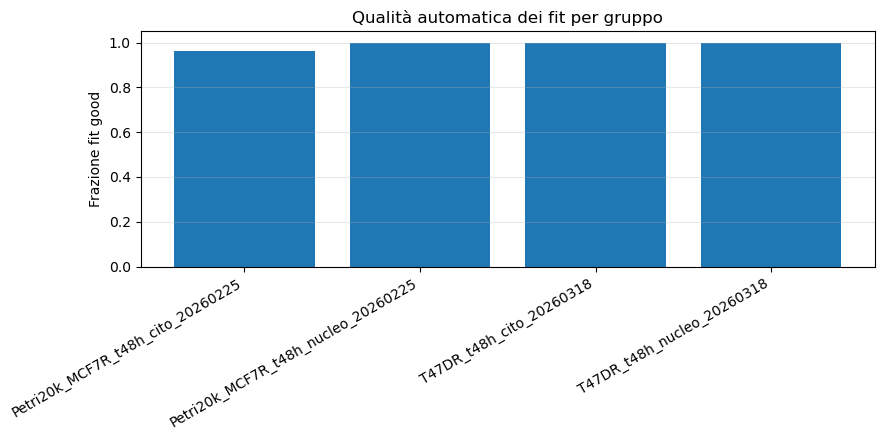

In [36]:

# Barplot frazione fit buoni per gruppo
plt.figure(figsize=(9, 4.5))
plt.bar(quality_pivot.index, quality_pivot["good_fraction"])
plt.ylabel("Frazione fit good")
plt.title("Qualità automatica dei fit per gruppo")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "good_fit_fraction_by_group.png", dpi=160, bbox_inches="tight")
plt.show()



## 4. Dataset per analisi statistica

Per le statistiche principali useremo inizialmente solo i fit `good`.

Puoi cambiare questa scelta includendo anche `suspicious`, ma per un primo risultato pulito è meglio essere conservativi.


In [37]:

USE_FLAGS = ["good"]   # puoi provare ["good", "suspicious"] se vuoi essere meno conservativo

ana = df[
    df["fit_quality_flag"].isin(USE_FLAGS)
    & np.isfinite(df["A"])
    & (df["A"] > 0)
    & np.isfinite(df["logA"])
].copy()

print("Curve totali:", len(df))
print("Curve usate per statistica:", len(ana))
print("Flag usati:", USE_FLAGS)

display(ana[["csv_file", "group", "sample", "region", "A", "logA", "fit_r2", "fit_quality_flag"]].head())


Curve totali: 257
Curve usate per statistica: 255
Flag usati: ['good']


,csv_file,group,sample,region,A,logA,fit_r2,fit_quality_flag
0,cito-0000_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,1.543671,0.434163,0.982332,good
1,cito-0005_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,1.654191,0.503312,0.972940,good
2,cito-0006_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,0.479768,-0.734453,0.976856,good
3,cito-0007_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,0.729394,-0.315542,0.982288,good
4,cito-0008_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,MCF7R,cito,0.962277,-0.038453,0.963774,good



## 5. Distribuzione globale di \(A\) e \(\log A\)


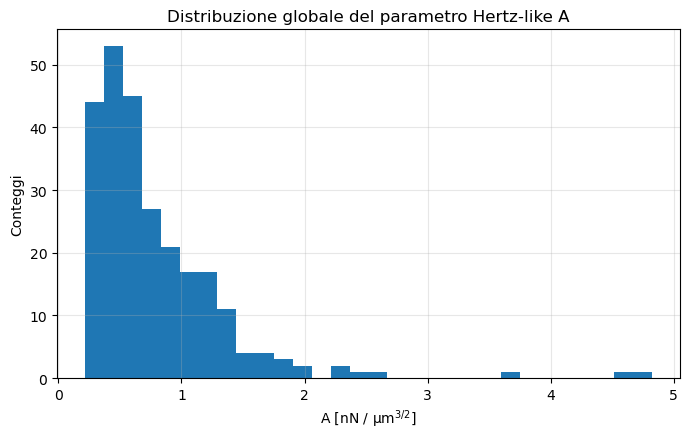

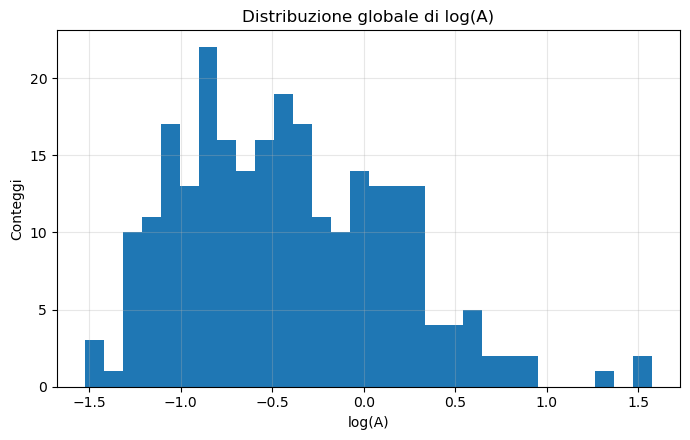

In [38]:

plt.figure(figsize=(7, 4.5))
plt.hist(ana["A"].dropna(), bins=30)
plt.xlabel(r"A [nN / µm$^{3/2}$]")
plt.ylabel("Conteggi")
plt.title("Distribuzione globale del parametro Hertz-like A")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "hist_A_global.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4.5))
plt.hist(ana["logA"].dropna(), bins=30)
plt.xlabel(r"log(A)")
plt.ylabel("Conteggi")
plt.title("Distribuzione globale di log(A)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "hist_logA_global.png", dpi=160, bbox_inches="tight")
plt.show()



## 6. Statistiche descrittive per gruppo


In [39]:

def q16(x): return np.nanquantile(x, 0.16)
def q84(x): return np.nanquantile(x, 0.84)
def q025(x): return np.nanquantile(x, 0.025)
def q975(x): return np.nanquantile(x, 0.975)

group_stats = ana.groupby("group").agg(
    n=("A", "size"),
    A_mean=("A", "mean"),
    A_std=("A", "std"),
    A_median=("A", "median"),
    A_q16=("A", q16),
    A_q84=("A", q84),
    logA_mean=("logA", "mean"),
    logA_std=("logA", "std"),
    logA_median=("logA", "median"),
    logA_q16=("logA", q16),
    logA_q84=("logA", q84),
    median_fit_r2=("fit_r2", "median"),
    median_rmse_nN=("fit_rmse_nN", "median"),
    median_baseline_noise_pN=("baseline_noise_pN", "median"),
).reset_index()

display(group_stats)

group_stats.to_csv(TABLES_DIR / "descriptive_stats_by_group.csv", index=False)
print("Saved:", TABLES_DIR / "descriptive_stats_by_group.csv")


,group,n,A_mean,A_std,A_median,A_q16,A_q84,logA_mean,logA_std,logA_median,logA_q16,logA_q84,median_fit_r2,median_rmse_nN,median_baseline_noise_pN
0,Petri20k_MCF7R_t48h_cito_20260225,53,0.886345,0.413277,0.821212,0.521952,1.281533,-0.218791,0.448277,-0.196974,-0.650197,0.247634,0.974784,0.018493,11.001852
1,Petri20k_MCF7R_t48h_nucleo_20260225,60,0.436733,0.162502,0.401471,0.298469,0.604987,-0.887636,0.337542,-0.912630,-1.209090,-0.502661,0.987886,0.013796,9.632690
2,T47DR_t48h_cito_20260318,59,0.948326,0.460355,0.894742,0.481379,1.268405,-0.163193,0.474942,-0.111219,-0.731137,0.237759,0.983660,0.013797,7.829958
3,T47DR_t48h_nucleo_20260318,83,0.871951,0.814525,0.637758,0.374864,1.293737,-0.379239,0.634402,-0.449796,-0.981334,0.257532,0.989253,0.011250,8.146487


Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/statistics/tables/descriptive_stats_by_group.csv


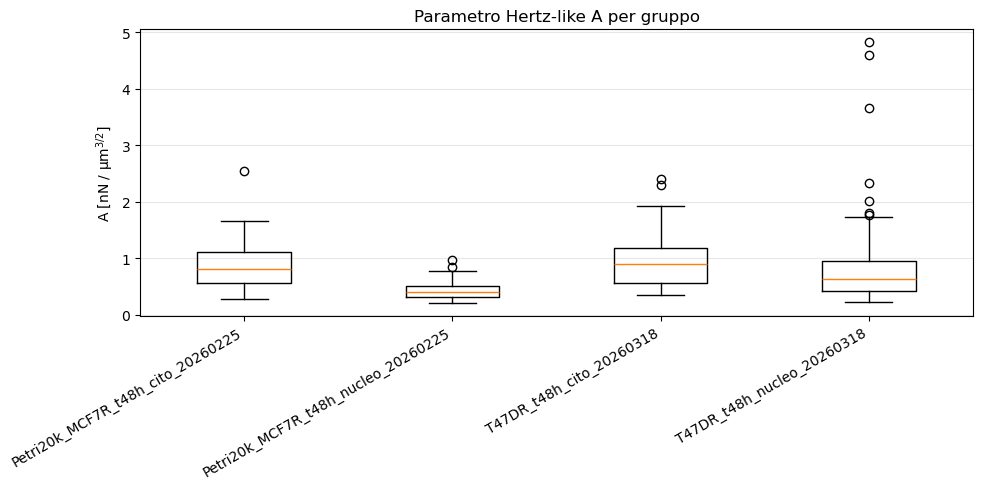

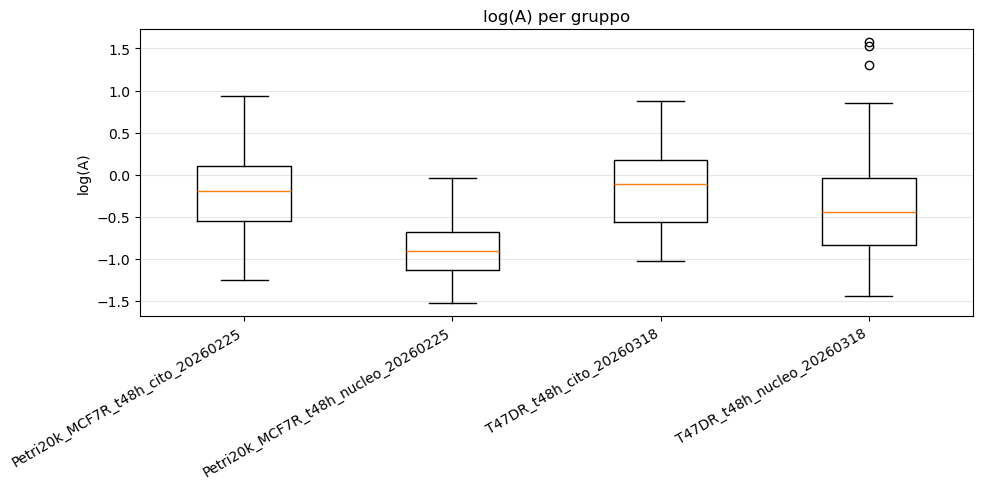

In [40]:

# Boxplot A per gruppo
groups = list(group_stats["group"])
data_A = [ana.loc[ana["group"] == g, "A"].dropna().values for g in groups]

plt.figure(figsize=(10, 5))
plt.boxplot(data_A, labels=groups, showfliers=True)
plt.xticks(rotation=30, ha="right")
plt.ylabel(r"A [nN / µm$^{3/2}$]")
plt.title("Parametro Hertz-like A per gruppo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "boxplot_A_by_group.png", dpi=160, bbox_inches="tight")
plt.show()

# Boxplot logA per gruppo
data_logA = [ana.loc[ana["group"] == g, "logA"].dropna().values for g in groups]

plt.figure(figsize=(10, 5))
plt.boxplot(data_logA, labels=groups, showfliers=True)
plt.xticks(rotation=30, ha="right")
plt.ylabel("log(A)")
plt.title("log(A) per gruppo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "boxplot_logA_by_group.png", dpi=160, bbox_inches="tight")
plt.show()



## 7. Confronto nucleo vs citoplasma

Qui aggreghiamo indipendentemente dal campione/cell line, solo come primo controllo esplorativo.


,region,n,A_median,A_q16,A_q84,logA_median,logA_q16,logA_q84
0,cito,112,0.850433,0.493151,1.269456,-0.162009,-0.706957,0.238589
1,nucleo,143,0.478851,0.324986,0.923996,-0.736365,-1.123976,-0.079130


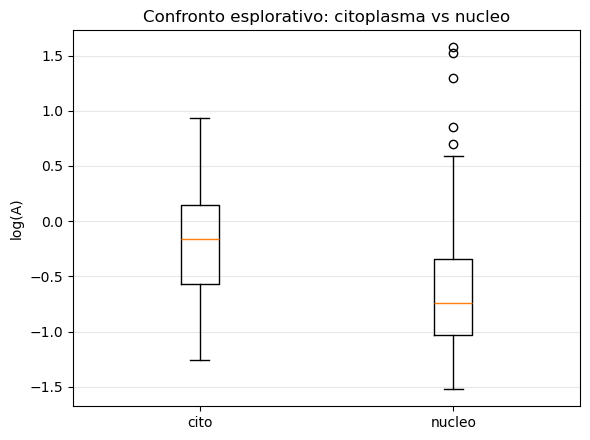

In [41]:

region_stats = ana.groupby("region").agg(
    n=("A", "size"),
    A_median=("A", "median"),
    A_q16=("A", q16),
    A_q84=("A", q84),
    logA_median=("logA", "median"),
    logA_q16=("logA", q16),
    logA_q84=("logA", q84),
).reset_index()

display(region_stats)
region_stats.to_csv(TABLES_DIR / "stats_by_region.csv", index=False)

regions = [r for r in ["cito", "nucleo"] if r in ana["region"].unique()]
data_region = [ana.loc[ana["region"] == r, "logA"].dropna().values for r in regions]

plt.figure(figsize=(6, 4.5))
plt.boxplot(data_region, labels=regions, showfliers=True)
plt.ylabel("log(A)")
plt.title("Confronto esplorativo: citoplasma vs nucleo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "boxplot_logA_cito_vs_nucleo.png", dpi=160, bbox_inches="tight")
plt.show()



## 8. Bootstrap delle mediane

Stimiamo l'incertezza sulla mediana di \(A\) e \(\log A\) per ogni gruppo usando bootstrap non parametrico.

Procedura:
1. per ogni gruppo, campioniamo con replacement le curve del gruppo;
2. calcoliamo la mediana;
3. ripetiamo molte volte;
4. prendiamo quantili 16/84 e 2.5/97.5.


In [42]:

rng = np.random.default_rng(12345)

def bootstrap_median_ci(x, n_boot=5000, ci=(0.16, 0.84, 0.025, 0.975)):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    n = len(x)
    if n == 0:
        return {
            "median": np.nan,
            "boot_q16": np.nan,
            "boot_q84": np.nan,
            "boot_q025": np.nan,
            "boot_q975": np.nan,
            "n": 0,
        }
    boots = np.empty(n_boot)
    for i in range(n_boot):
        sample = rng.choice(x, size=n, replace=True)
        boots[i] = np.nanmedian(sample)
    return {
        "median": float(np.nanmedian(x)),
        "boot_q16": float(np.nanquantile(boots, ci[0])),
        "boot_q84": float(np.nanquantile(boots, ci[1])),
        "boot_q025": float(np.nanquantile(boots, ci[2])),
        "boot_q975": float(np.nanquantile(boots, ci[3])),
        "n": int(n),
    }

boot_rows = []
for g, sub in ana.groupby("group"):
    out_A = bootstrap_median_ci(sub["A"].values)
    out_logA = bootstrap_median_ci(sub["logA"].values)
    boot_rows.append({
        "group": g,
        "n": out_A["n"],
        "A_median": out_A["median"],
        "A_boot_q16": out_A["boot_q16"],
        "A_boot_q84": out_A["boot_q84"],
        "A_boot_q025": out_A["boot_q025"],
        "A_boot_q975": out_A["boot_q975"],
        "logA_median": out_logA["median"],
        "logA_boot_q16": out_logA["boot_q16"],
        "logA_boot_q84": out_logA["boot_q84"],
        "logA_boot_q025": out_logA["boot_q025"],
        "logA_boot_q975": out_logA["boot_q975"],
    })

boot_group = pd.DataFrame(boot_rows).sort_values("group")
display(boot_group)

boot_group.to_csv(TABLES_DIR / "bootstrap_medians_by_group.csv", index=False)
print("Saved:", TABLES_DIR / "bootstrap_medians_by_group.csv")


,group,n,A_median,A_boot_q16,A_boot_q84,A_boot_q025,A_boot_q975,logA_median,logA_boot_q16,logA_boot_q84,logA_boot_q025,logA_boot_q975
0,Petri20k_MCF7R_t48h_cito_20260225,53,0.821212,0.724601,0.926528,0.695503,0.964510,-0.196974,-0.346913,-0.076311,-0.363120,-0.036135
1,Petri20k_MCF7R_t48h_nucleo_20260225,60,0.401471,0.355565,0.407657,0.348945,0.425734,-0.912630,-1.030140,-0.897330,-1.049682,-0.857077
2,T47DR_t48h_cito_20260318,59,0.894742,0.807626,1.028762,0.683383,1.086702,-0.111219,-0.213656,0.028356,-0.375566,0.085737
3,T47DR_t48h_nucleo_20260318,83,0.637758,0.563961,0.645623,0.536883,0.690932,-0.449796,-0.572770,-0.437540,-0.621974,-0.369714


Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/statistics/tables/bootstrap_medians_by_group.csv


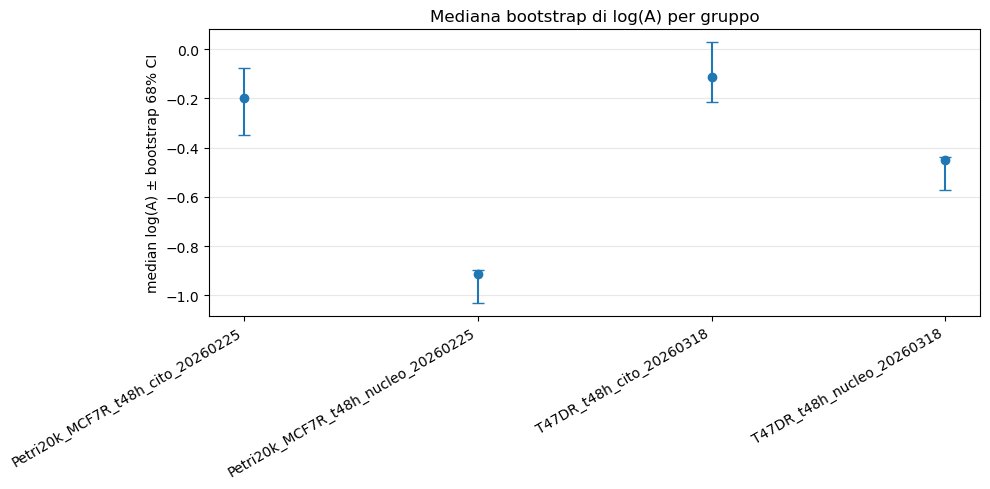

In [43]:

# Plot mediana logA con intervallo bootstrap 68%
x = np.arange(len(boot_group))
y = boot_group["logA_median"].values
yerr_low = y - boot_group["logA_boot_q16"].values
yerr_high = boot_group["logA_boot_q84"].values - y

plt.figure(figsize=(10, 5))
plt.errorbar(x, y, yerr=[yerr_low, yerr_high], fmt="o", capsize=4)
plt.xticks(x, boot_group["group"], rotation=30, ha="right")
plt.ylabel("median log(A) ± bootstrap 68% CI")
plt.title("Mediana bootstrap di log(A) per gruppo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "bootstrap_median_logA_by_group.png", dpi=160, bbox_inches="tight")
plt.show()



## 9. Bootstrap differenza nucleo - citoplasma

Calcoliamo la differenza tra mediane:

\[
\Delta = \mathrm{median}[\log A]_{\mathrm{nucleo}} - \mathrm{median}[\log A]_{\mathrm{cito}}
\]

Questa è una prima misura esplorativa, non ancora una conclusione biologica.


Delta = median(logA)_nucleo - median(logA)_cito
Delta median: -0.5743555681308083
68% CI: -0.6759634627020565 -0.451176327327994
95% CI: -0.7637284433014581 -0.33797806494389426


,comparison,delta_median_logA,delta_boot_q16,delta_boot_q84,delta_boot_q025,delta_boot_q975
0,nucleo_minus_cito,-0.574356,-0.675963,-0.451176,-0.763728,-0.337978


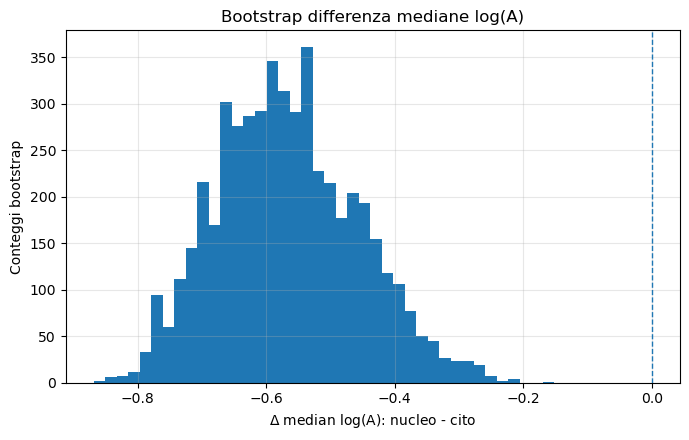

In [44]:

def bootstrap_difference_of_medians(x, y, n_boot=5000):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = x[np.isfinite(x)]
    y = y[np.isfinite(y)]

    if len(x) == 0 or len(y) == 0:
        return None

    boots = np.empty(n_boot)
    for i in range(n_boot):
        xb = rng.choice(x, size=len(x), replace=True)
        yb = rng.choice(y, size=len(y), replace=True)
        boots[i] = np.nanmedian(xb) - np.nanmedian(yb)

    return {
        "delta_median": float(np.nanmedian(x) - np.nanmedian(y)),
        "boot_q16": float(np.nanquantile(boots, 0.16)),
        "boot_q84": float(np.nanquantile(boots, 0.84)),
        "boot_q025": float(np.nanquantile(boots, 0.025)),
        "boot_q975": float(np.nanquantile(boots, 0.975)),
        "boots": boots,
    }

logA_nucleo = ana.loc[ana["region"] == "nucleo", "logA"].values
logA_cito = ana.loc[ana["region"] == "cito", "logA"].values

delta_region = bootstrap_difference_of_medians(logA_nucleo, logA_cito)

if delta_region is not None:
    print("Delta = median(logA)_nucleo - median(logA)_cito")
    print("Delta median:", delta_region["delta_median"])
    print("68% CI:", delta_region["boot_q16"], delta_region["boot_q84"])
    print("95% CI:", delta_region["boot_q025"], delta_region["boot_q975"])

    delta_table = pd.DataFrame([{
        "comparison": "nucleo_minus_cito",
        "delta_median_logA": delta_region["delta_median"],
        "delta_boot_q16": delta_region["boot_q16"],
        "delta_boot_q84": delta_region["boot_q84"],
        "delta_boot_q025": delta_region["boot_q025"],
        "delta_boot_q975": delta_region["boot_q975"],
    }])
    display(delta_table)
    delta_table.to_csv(TABLES_DIR / "bootstrap_delta_logA_nucleo_minus_cito.csv", index=False)

    plt.figure(figsize=(7, 4.5))
    plt.hist(delta_region["boots"], bins=40)
    plt.axvline(0, ls="--", lw=1)
    plt.xlabel(r"$\Delta$ median log(A): nucleo - cito")
    plt.ylabel("Conteggi bootstrap")
    plt.title("Bootstrap differenza mediane log(A)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "bootstrap_delta_logA_nucleo_minus_cito.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Non ci sono abbastanza dati per confrontare nucleo e cito.")



## 10. Migliori e peggiori fit

Utile per creare una slide/report: mostrare esempi di fit buoni e casi problematici.


In [45]:

good_examples = (
    df[df["fit_status"] == "ok"]
    .sort_values(["fit_quality_flag", "fit_r2"], ascending=[True, False])
)

best = df[(df["fit_status"] == "ok") & np.isfinite(df["fit_r2"])].sort_values("fit_r2", ascending=False).head(15)
worst = df[(df["fit_status"] == "ok") & np.isfinite(df["fit_r2"])].sort_values("fit_r2", ascending=True).head(15)

display(best[["csv_file", "group", "fit_quality_flag", "A", "logA", "fit_r2", "fit_rmse_nN", "fit_plot"]])
display(worst[["csv_file", "group", "fit_quality_flag", "A", "logA", "fit_r2", "fit_rmse_nN", "fit_plot"]])

best.to_csv(TABLES_DIR / "best_fits.csv", index=False)
worst.to_csv(TABLES_DIR / "worst_fits.csv", index=False)


,csv_file,group,fit_quality_flag,A,logA,fit_r2,fit_rmse_nN,fit_plot
227,nucleo-0058_segment0.csv,T47DR_t48h_nucleo_20260318,good,0.613268,-0.488954,0.994782,0.011491,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
216,nucleo-0046_segment0.csv,T47DR_t48h_nucleo_20260318,good,0.458487,-0.779822,0.994674,0.010585,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
241,nucleo-0073_segment0.csv,T47DR_t48h_nucleo_20260318,good,0.424095,-0.857798,0.994235,0.010303,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
190,nucleo-0018_segment0.csv,T47DR_t48h_nucleo_20260318,good,0.537426,-0.620965,0.994006,0.010907,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
68,nucleo-0016_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,good,0.356957,-1.030140,0.993915,0.011489,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
73,nucleo-0023_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,good,0.964737,-0.035899,0.993852,0.013219,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
185,nucleo-0013_segment0.csv,T47DR_t48h_nucleo_20260318,good,1.020594,0.020385,0.993843,0.011179,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
98,nucleo-0061_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,good,0.646104,-0.436795,0.993812,0.010423,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
213,nucleo-0043_segment0.csv,T47DR_t48h_nucleo_20260318,good,0.404495,-0.905115,0.993727,0.010634,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
96,nucleo-0059_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,good,0.392197,-0.935990,0.993588,0.011906,/Users/gmoretti/Work/AFM/Code_General/afm_outp...


,csv_file,group,fit_quality_flag,A,logA,fit_r2,fit_rmse_nN,fit_plot
5,cito-0009_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,suspicious,0.542173,-0.612170,0.844239,0.061349,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
31,cito-0052_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,suspicious,0.590698,-0.526450,0.893798,0.043722,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
51,cito-0082_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,good,0.867490,-0.142151,0.920334,0.021839,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
8,cito-0013_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,good,0.641539,-0.443886,0.934424,0.017244,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
145,cito-0050_segment0.csv,T47DR_t48h_cito_20260318,good,0.958721,-0.042156,0.946921,0.022908,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
50,cito-0081_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,good,1.308379,0.268789,0.947120,0.036477,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
53,cito-0085_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,good,1.306921,0.267674,0.949318,0.026640,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
19,cito-0032_segment0.csv,Petri20k_MCF7R_t48h_cito_20260225,good,0.926528,-0.076311,0.953933,0.024008,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
134,cito-0034_segment0.csv,T47DR_t48h_cito_20260318,good,1.228982,0.206186,0.954275,0.024007,/Users/gmoretti/Work/AFM/Code_General/afm_outp...
93,nucleo-0054_segment0.csv,Petri20k_MCF7R_t48h_nucleo_20260225,good,0.325353,-1.122846,0.955422,0.010927,/Users/gmoretti/Work/AFM/Code_General/afm_outp...



## 11. Summary finale automatico


In [46]:
summary_lines = []

summary_lines.append("# AFM Hertz-like fit summary\n")
summary_lines.append(f"Total curves in fit table: {len(df)}\n")
summary_lines.append(f"Curves used for statistical analysis: {len(ana)}\n")
summary_lines.append(f"Quality flags used: {USE_FLAGS}\n\n")

summary_lines.append("## Fit quality by group\n")
summary_lines.append("```text\n")
summary_lines.append(quality_pivot.to_string())
summary_lines.append("\n```\n")

summary_lines.append("\n## Descriptive statistics by group\n")
summary_lines.append("```text\n")
summary_lines.append(group_stats.to_string(index=False))
summary_lines.append("\n```\n")

summary_lines.append("\n## Bootstrap medians by group\n")
summary_lines.append("```text\n")
summary_lines.append(boot_group.to_string(index=False))
summary_lines.append("\n```\n")

if delta_region is not None:
    summary_lines.append("\n## Bootstrap comparison: nucleo - cito\n")
    summary_lines.append("```text\n")
    summary_lines.append(delta_table.to_string(index=False))
    summary_lines.append("\n```\n")

summary_md = "\n".join(summary_lines)

summary_path = STATS_DIR / "analysis_summary.md"
summary_path.write_text(summary_md, encoding="utf-8")

print("Saved:", summary_path)
print(summary_md[:2000])

Saved: /Users/gmoretti/Work/AFM/Code_General/afm_output/fit_hertz_like/statistics/analysis_summary.md
# AFM Hertz-like fit summary

Total curves in fit table: 257

Curves used for statistical analysis: 255

Quality flags used: ['good']


## Fit quality by group

```text

fit_quality_flag                     total  good  suspicious  bad  good_fraction
group                                                                           
Petri20k_MCF7R_t48h_cito_20260225       55    53           2    0       0.963636
Petri20k_MCF7R_t48h_nucleo_20260225     60    60           0    0       1.000000
T47DR_t48h_cito_20260318                59    59           0    0       1.000000
T47DR_t48h_nucleo_20260318              83    83           0    0       1.000000

```


## Descriptive statistics by group

```text

                              group  n   A_mean    A_std  A_median    A_q16    A_q84  logA_mean  logA_std  logA_median  logA_q16  logA_q84  median_fit_r2  median_rmse_nN  median_baseline_noi


## Output prodotti

Alla fine trovi:

```text
afm_output/fit_hertz_like/statistics/
├── plots/
│   ├── good_fit_fraction_by_group.png
│   ├── hist_A_global.png
│   ├── hist_logA_global.png
│   ├── boxplot_A_by_group.png
│   ├── boxplot_logA_by_group.png
│   ├── boxplot_logA_cito_vs_nucleo.png
│   ├── bootstrap_median_logA_by_group.png
│   └── bootstrap_delta_logA_nucleo_minus_cito.png
├── tables/
│   ├── fit_results_cleaned.csv
│   ├── fit_quality_by_group.csv
│   ├── descriptive_stats_by_group.csv
│   ├── stats_by_region.csv
│   ├── bootstrap_medians_by_group.csv
│   ├── bootstrap_delta_logA_nucleo_minus_cito.csv
│   ├── best_fits.csv
│   └── worst_fits.csv
└── analysis_summary.md
```

Questo notebook è il primo vero livello di analisi statistica aggregata.
